In [1]:
import os, sys, json, random, time
from pathlib import Path

# --- point this at the project root (folder with config.py, data/, models/, notebook_helpers.py)
REPO_ROOT = os.environ.get("COURT_REPO_ROOT", "../court_case_transformer_project")
if REPO_ROOT and Path(REPO_ROOT).exists():
    sys.path.insert(0, str(Path(REPO_ROOT).resolve()))

# --- the uploaded spreadsheet is the input
INPUT_XLSX = os.environ.get(
    "INPUT_XLSX",
    "balanced_case_samples_with_embeddings.xlsx",   # <- place the file next to this notebook
)

CONFIG = {
    "seed": 42,
    "device": "auto",                       # auto | cpu | cuda | cuda:0
    "input_xlsx": INPUT_XLSX,
    "outputs_dir": "./outputs",             # where the paper artifacts are written
    "cache_root": "./cache/transformers",   # CacheDirectoryManager base
    "run_name": "balanced_with_embeddings",

    # train
    "validation_strategy": "predefined_folds",  # predefined_folds (use test_fold) | k_fold | train_val_split
    "k_fold_num_folds": 5,
    "epochs": 20,
    "batch_size": 16,
    "weighted_loss": True,
    "use_mixed_precision": True,
    "use_learning_rate_scheduler": True,
    "gradient_clip_norm": 1.0,
    "val_split": 0.2,

    # evaluate
    "top_n_labels_to_display": 10,
    "run_baselines": True,

    # analyses
    "ig": {"enabled": True, "n_cases": 200, "n_steps": 30, "method": "IntegratedGradients", "top_n_words": 30},
    "sensitivity": {"enabled": True, "max_samples": 200, "top_n_labels": 8, "parallel": True,
                    "features": ["gender", "race", "age", "prior_case_count", "original_bond"]},
    "clustering": {"enabled": True, "projection": "tsne", "n_clusters": 6,
                   "max_samples_per_fold": None, "use_teacher_forcing": True},
}

Path(CONFIG["outputs_dir"]).mkdir(parents=True, exist_ok=True)
print("REPO_ROOT :", REPO_ROOT, "(on path)" if REPO_ROOT in sys.path[0:1] or Path(REPO_ROOT).exists() else "(NOT found)")
print("INPUT_XLSX:", CONFIG["input_xlsx"], "(exists)" if Path(CONFIG["input_xlsx"]).exists() else "(NOT found)")

REPO_ROOT : ../court_case_transformer_project (on path)
INPUT_XLSX: balanced_case_samples_with_embeddings.xlsx (exists)


In [2]:
def seed_everything(seed: int) -> None:
    """Single deterministic seed point. Prefers the repo's set_global_seed."""
    try:
        from notebook_helpers import set_global_seed
        set_global_seed(seed); return
    except Exception:
        pass
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    try:
        import numpy as np; np.random.seed(seed)
    except ImportError:
        pass
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

def resolve_device():
    import torch
    w = CONFIG["device"]
    if w == "auto":
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")
    return torch.device(w)

seed_everything(CONFIG["seed"])
print("seed set:", CONFIG["seed"])

seed set: 42


In [3]:
import numpy as np
from openpyxl import load_workbook
from collections import defaultdict

def load_sequences_from_xlsx(path, parse_embeddings=True, verbose=True):
    t0 = time.time()
    wb = load_workbook(path, read_only=True, data_only=True)
    ws = wb[wb.sheetnames[0]]
    rows = ws.iter_rows(values_only=True)
    header = next(rows)
    col = {h: i for i, h in enumerate(header)}

    def get(r, name, default=None):
        i = col.get(name)
        return r[i] if i is not None and i < len(r) else default

    buckets = defaultdict(list)   # sequence_idx -> list of proceeding dicts
    fold_of = {}
    n = 0
    for r in rows:
        sidx = get(r, "sequence_idx", get(r, "sequence_index"))
        if sidx is None:
            continue
        labs = get(r, "labels") or ""
        emb_raw = get(r, "embedding")
        charges_raw = get(r, "charges") or ""
        proc = {
            "step_idx": get(r, "step_idx", get(r, "proceeding_index", 0)),
            "proceeding_id": get(r, "proceeding_id"),
            "proceeding_type": get(r, "proceeding_type"),
            "date": get(r, "date"),
            "text": get(r, "text"),
            "embedding": (np.asarray(json.loads(emb_raw), dtype=np.float32)
                          if (parse_embeddings and emb_raw) else None),
            "original_bond": get(r, "original_bond"),
            "sum_of_bonds": get(r, "sum_of_bonds"),
            "race_id": get(r, "race_id"),
            "gender_id": get(r, "gender_id"),
            "age": get(r, "age"),
            "magistrate_section": get(r, "magistrate_section"),
            "charges": [c.strip() for c in charges_raw.split("|") if c.strip()],
            "num_charges": get(r, "num_charges"),
            "mag_num": get(r, "mag_num"),
            "case_id": get(r, "case_id"),
            "defendant_id": get(r, "defendant_id"),
            "labels": [x for x in labs.split("|") if x],
        }
        buckets[sidx].append(proc)
        fold_of[sidx] = get(r, "test_fold")
        n += 1

    sequences, label_sequences_raw, fold_ids, case_ids = [], [], [], []
    for sidx in sorted(buckets):
        steps = sorted(buckets[sidx], key=lambda p: (p["step_idx"] if p["step_idx"] is not None else 0))
        sequences.append(steps)
        label_sequences_raw.append([s["labels"] for s in steps])
        fold_ids.append(fold_of[sidx])
        case_ids.append(sidx)

    if verbose:
        emb_dim = next((s["embedding"].shape[0] for seq in sequences for s in seq
                        if s["embedding"] is not None), None)
        labels = sorted({l for seq in label_sequences_raw for step in seq for l in step})
        from collections import Counter
        print(f"parsed {n} proceedings -> {len(sequences)} cases in {time.time()-t0:.1f}s")
        print(f"embedding dim: {emb_dim} | label vocab: {len(labels)}")
        print(f"fold sizes (cases): {dict(sorted(Counter(fold_ids).items()))}")
        lens = [len(s) for s in sequences]
        print(f"sequence length min/median/max: {min(lens)}/{sorted(lens)[len(lens)//2]}/{max(lens)}")
    return sequences, label_sequences_raw, fold_ids, case_ids

sequences, label_sequences_raw, fold_ids, case_ids = load_sequences_from_xlsx(CONFIG["input_xlsx"])

parsed 19459 proceedings -> 2533 cases in 9.2s
embedding dim: 768 | label vocab: 20
fold sizes (cases): {1: 507, 2: 507, 3: 507, 4: 506, 5: 506}
sequence length min/median/max: 1/6/83


In [4]:
# Quick peek at one reconstructed case
ex = sequences[0]
print("case_id:", case_ids[0], "| fold:", fold_ids[0], "| steps:", len(ex))
for s in ex[:3]:
    print(f"  step {s['step_idx']:>2} [{s['proceeding_type']}] "
          f"emb={None if s['embedding'] is None else s['embedding'].shape} "
          f"bond={s['original_bond']} charges={len(s['charges'])} labels={s['labels']}")

case_id: 0 | fold: 4 | steps: 11
  step  0 [mag] emb=(768,) bond=25000 charges=2 labels=['FIRST_APPEARANCE_HEARING_OCCURRED', 'BOND_SET', 'THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER', 'PROBABLE_CAUSE_FOUND']
  step  1 [mag] emb=(768,) bond=25000 charges=2 labels=['CHARGES_REFUSED']
  step  2 [cdc] emb=(768,) bond=None charges=2 labels=['CONTINUANCE_OCCURRED']


In [5]:
from collections import Counter

def _charges_to_dict(charge_names):
    """The model's ChargeVocabulary.encode iterates case_charges.items(), so charges
    must be a DICT, not a list. The vocab is built from charge *names*, so key by name;
    the value carries the occurrence count (name2idx path in encode)."""
    return {name: {"name": name, "count": c} for name, c in Counter(charge_names).items()}

def _coerce_id(v, default):
    """race_id/gender_id feed nn.Embedding -> must be a plain int. The export uses
    None or '' for unknown defendants (e.g. mag_unknown_*), so map those to the
    model's 'unknown' slot (race=5 of 6, gender=2 of 3)."""
    try:
        if v is None or (isinstance(v, str) and v.strip() == ""):
            return default
        return int(float(v))
    except (TypeError, ValueError):
        return default

def _coerce_num(v, default):
    """age feeds a Linear after a numeric clip -> must be a number, not None/''."""
    try:
        if v is None or (isinstance(v, str) and v.strip() == ""):
            return default
        return float(v)
    except (TypeError, ValueError):
        return default

def build_model_ready_sequences(sequences):
    """Reshape reconstructed proceedings into the per-step dicts CaseTransformerModel reads.

    Keys mirror what model.encode_proceeding() looks up via pdict.get(...):
      race_id, gender_id, age, charges (dict), proceeding_id (-> cached embedding),
      type (mag/cdc -> court_type), magistrate_section, original_bond, sum_of_bonds, date.
    Note: pdict.get(key, default) only uses the default when the key is ABSENT; an
    explicit None still reaches the model, so demographics are coerced here.
    """
    out = []
    for case in sequences:
        steps = []
        for p in case:
            steps.append({
                "proceeding_id": p["proceeding_id"],     # -> cached BERT embedding lookup
                "type": p["proceeding_type"],            # model reads "type" (not proceeding_type)
                "text": p["text"],
                "magistrate_section": p["magistrate_section"] or "unknown",
                "race_id": _coerce_id(p["race_id"], 5),      # 5 = unknown (num_races=6)
                "gender_id": _coerce_id(p["gender_id"], 2),  # 2 = unknown (num_genders=3)
                "age": _coerce_num(p["age"], 25),            # 25 = model default
                "charges": _charges_to_dict(p["charges"]),   # DICT (was a list -> AttributeError)
                "original_bond": p["original_bond"], "sum_of_bonds": p["sum_of_bonds"],  # None ok
                "num_charges": p["num_charges"], "date": p["date"],                      # None ok
                "mag_num": p["mag_num"], "case_id": p["case_id"],
                "defendant_id": p["defendant_id"], "step_idx": p["step_idx"],
                # Not in the export -> model falls back to safe defaults, so the "prior"
                # components are zeroed: prior_case_count=0, all_prior_charges={},
                # true_prior_labels->zeros. Derive from sequence order if you need them.
            })
        out.append(steps)
    return out

model_sequences = build_model_ready_sequences(sequences)
print("model-ready cases:", len(model_sequences))
print("example charges dict:", list(model_sequences[0][0]["charges"].items())[:2])
print("example type:", model_sequences[0][0]["type"])

model-ready cases: 2533
example charges dict: [('SIMPLE BURGLARY', {'name': 'SIMPLE BURGLARY', 'count': 1}), ('ILL POSS STOLEN THINGS $500 TO $1500', {'name': 'ILL POSS STOLEN THINGS $500 TO $1500', 'count': 1})]
example type: mag


In [6]:
RESUBSAMPLE = False
N_SUBSAMPLE = 300

if RESUBSAMPLE:
    seed_everything(CONFIG["seed"])
    keep = sorted(random.sample(range(len(sequences)), min(N_SUBSAMPLE, len(sequences))))
    sequences        = [sequences[i] for i in keep]
    model_sequences  = [model_sequences[i] for i in keep]
    label_sequences_raw = [label_sequences_raw[i] for i in keep]
    fold_ids         = [fold_ids[i] for i in keep]
    case_ids         = [case_ids[i] for i in keep]
    print("subsampled to", len(sequences), "cases")
else:
    print("using full balanced sample:", len(sequences), "cases")

using full balanced sample: 2533 cases


In [7]:
# --- requires the repo on sys.path ---
from training.label_processor import EnhancedLabelProcessor
from config import get_model_config

model_cfg = get_model_config()
LABEL_NAMES = model_cfg.LABEL_NAMES
label_processor = EnhancedLabelProcessor(LABEL_NAMES)
label_processor.fit(LABEL_NAMES)
print("labels:", len(LABEL_NAMES))

device = resolve_device()
print("device:", device)

from utils.cache_directory_utils import CacheDirectoryManager
cache = CacheDirectoryManager(base_path=str(Path(CONFIG["cache_root"]) / CONFIG["run_name"]))

✅ Fitted MultiLabelBinarizer with 20 predefined classes:
   Labels: ['FIRST_APPEARANCE_HEARING_OCCURRED', 'BOND_SET', 'BOND_NOT_SET', 'DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE', 'THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER', 'ANKLE_MONITORING_IMPOSED', 'DOMESTIC_STAY_AWAY_ORDER_IMPOSED', 'CHARGES_ACCEPTED', 'CHARGES_REFUSED', 'PROBABLE_CAUSE_FOUND', 'PROBABLE_CAUSE_NOT_FOUND', 'DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT', 'THE_STATE_WAS_NOT_PRESENT', 'PRE_TRIAL_CONFERENCE_HELD', 'CONTINUANCE_OCCURRED', 'PLED_GUILTY_TO_CHARGES', 'PLED_NOT_GUILTY_TO_CHARGES', 'TRIAL_VERDICT_REACHED', 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED', 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED']
labels: 20
device: cuda


In [8]:
import h5py, pickle as _pickle
import pandas as pd

# ---------------------------------------------------------------------------
# Two things create_model_from_data() needs that the drive normally provides —
# both rebuilt here straight from the spreadsheet, so no Google Drive is touched:
#   (1) a court_data-shaped dict for date-range + charge/magistrate vocabularies
#   (2) the BERT text embeddings written into the HDF5 cache the model reads at
#       runtime (embeddings.h5 + proceeding_index.pkl), keyed by proceeding_id.
# ---------------------------------------------------------------------------

def build_court_data_lite(sequences):
    """Minimal court_data: mag/cdc proceeding tables + a charges table."""
    mag_rows, cdc_rows, charge_names = [], [], set()
    for case in sequences:
        for p in case:
            row = {"proceeding_id": p["proceeding_id"], "date": p["date"],
                   "magistrate_section": p["magistrate_section"], "text": p["text"]}
            (mag_rows if p["proceeding_type"] == "mag" else cdc_rows).append(row)
            for c in p["charges"]:
                charge_names.add(c)
    return {
        "mag": pd.DataFrame(mag_rows),
        "cdc": pd.DataFrame(cdc_rows),
        # fallback charge-vocab path in create_vocabularies_from_data reads `charge_name`
        "charges": pd.DataFrame({"charge_name": sorted(charge_names) or ["UNKNOWN_CHARGE"]}),
    }

def inject_embeddings_into_cache(sequences, cache, out_dim=768, force=False):
    """Write the spreadsheet's inline embeddings into the model's HDF5 cache.

    Matches BertEmbeddingExtraction's schema exactly: a single float32 dataset
    'embeddings' of shape (N, out_dim) plus a proceeding_id -> row index pickle,
    so bert_embedding_check() finds the cache and the model reads THESE vectors
    instead of recomputing BERT.
    """
    bert_dir = cache.get_cache_dir("bert")
    emb_file = bert_dir / "embeddings.h5"
    idx_file = bert_dir / "proceeding_index.pkl"
    proc_file = bert_dir / "processed_index.json"
    if emb_file.exists() and idx_file.exists() and not force:
        print("BERT embedding cache already present:", bert_dir); return

    index, vecs = {}, []
    for case in sequences:
        for p in case:
            pid, emb = p["proceeding_id"], p["embedding"]
            if pid is None or emb is None or pid in index:
                continue
            index[pid] = len(vecs)
            vecs.append(np.asarray(emb, dtype=np.float32))
    arr = np.vstack(vecs).astype("float32")
    with h5py.File(emb_file, "w") as h5:
        ds = h5.create_dataset("embeddings", shape=arr.shape, maxshape=(None, out_dim),
                               dtype="float32", chunks=(1, out_dim))
        ds[:] = arr
    with open(idx_file, "wb") as f:
        _pickle.dump(index, f)
    with open(proc_file, "w") as f:
        json.dump(list(index.keys()), f)
    print(f"wrote {arr.shape[0]} embeddings ({arr.shape[1]}-d) -> {emb_file}")

court_data_lite = build_court_data_lite(sequences)
inject_embeddings_into_cache(sequences, cache, out_dim=768)
print("mag rows:", len(court_data_lite["mag"]), "| cdc rows:", len(court_data_lite["cdc"]),
      "| charges:", len(court_data_lite["charges"]))

BERT embedding cache already present: cache/transformers/balanced_with_embeddings/bert_streaming
mag rows: 5807 | cdc rows: 13652 | charges: 709


In [9]:
from models.transformer_creation import create_model_from_data

# embeddings in the file are 768-d (bert-base) -> the model's text dim matches
BERT_OUT_DIM = 768

def create_fresh_model():
    seed_everything(CONFIG["seed"])          # identical init across folds
    return create_model_from_data(
        data=court_data_lite,                 # <- real data dict (was None: caused the AttributeError)
        cache_dir=cache.get_cache_dir("bert"),
        device=device, cache_manager=cache,
        parameters_dict={**CONFIG, "random_seed": CONFIG["seed"]},
        bert_out_dim=BERT_OUT_DIM,
    )

In [10]:
from training.trainer import train_case_transformer_with_mlb

def train_predefined_folds(model_sequences, label_sequences_raw, fold_ids):
    """Train one model per value of `test_fold`, holding that fold out for validation."""
    data = list(zip(model_sequences, label_sequences_raw))
    folds_sorted = sorted(set(fold_ids))
    results = []
    for f in folds_sorted:
        seed_everything(CONFIG["seed"])
        train_idx = [i for i, fi in enumerate(fold_ids) if fi != f]
        val_idx   = [i for i, fi in enumerate(fold_ids) if fi == f]
        train_data = [data[i] for i in train_idx]
        val_data   = [data[i] for i in val_idx]
        print(f"\n=== fold {f}: train {len(train_data)} / val {len(val_data)} ===")
        out_dir = cache.get_cache_dir("models") / f"predefined_fold_{f}"
        out_dir.mkdir(parents=True, exist_ok=True)
        model = create_fresh_model()
        trained, _logger = train_case_transformer_with_mlb(
            model=model, sequences_and_labels=train_data, label_processor=label_processor,
            val_data=val_data, epochs=CONFIG["epochs"], batch_size=CONFIG["batch_size"],
            device=device, directory_for_output=out_dir,
            use_mixed_precision=CONFIG["use_mixed_precision"],
            use_learning_rate_scheduler=CONFIG["use_learning_rate_scheduler"],
            gradient_clip_norm=CONFIG["gradient_clip_norm"],
            weighted_loss=CONFIG["weighted_loss"], cache_manager=cache,
            optional_tag=f"fold_{f}",
        )
        results.append({"fold": f, "model": trained, "val": val_data})
    return results


=== fold 1: train 2026 / val 507 ===
Analyzing date range in data...
MAG data - Date range: 2009-01-11 00:00:00 to 2025-11-13 00:00:00, Count: 5807
CDC data - Date range: 2018-03-07 00:00:00 to 2025-11-14 00:00:00, Count: 13652
Overall date range in data: 2009 - 2025
Date range updated: 2009 to 2025
Date range in data: 2009 to 2025
Using MIN_YEAR=2009, NUM_YEARS=17
Updated temporal dimensions: 204 features (12 months × 17 years)
Creating charge vocabulary from list with 709 unique charges
  Sources: charges (709 unique)
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.

📈 LR Scheduler: OneCycleLR
   Steps per epoch: 127
   Total steps: 2540
   Max LR: 1.00e-04
Before training - Allocated: 113.21 MB, Reserved: 142.00 MB
🚀 Starting training with MultiLabelBinarizer
   Label processor: 20 labels
   Training sequences: 2026
   Validation sequences: 507
Epoch 1/20 - Allocated: 113.21 MB, R

Epoch 1/20: 100%|██████████| 127/127 [00:50<00:00,  2.49it/s, loss=1.0322, lr=1.04e-05, timesteps=66] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2575
   Recall:    0.2575
   F1-Score:  0.2575
   Steps processed: 3,875
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1032
  BOND_SET                                              740
  PRE_TRIAL_CONFERENCE_HELD                             659
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       618
  FIRST_APPEARANCE_HEARING_OCCURRED                     512
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 379
  CHARGES_REFUSED                                       356
  PLED_NOT_GUILTY_TO_CHARGES                            334
  PROBABLE_CAUSE_FOUND                                  288
  PLED_GUILTY_TO_CHARGES                                218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                197
  BOND_NOT_SET                                          170
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

Epoch 2/20: 100%|██████████| 127/127 [00:50<00:00,  2.49it/s, loss=1.0110, lr=2.81e-05, timesteps=58] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3297
   Recall:    0.3297
   F1-Score:  0.3297
   Steps processed: 3,875
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1032
  BOND_SET                                              740
  PRE_TRIAL_CONFERENCE_HELD                             659
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       618
  FIRST_APPEARANCE_HEARING_OCCURRED                     512
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 379
  CHARGES_REFUSED                                       356
  PLED_NOT_GUILTY_TO_CHARGES                            334
  PROBABLE_CAUSE_FOUND                                  288
  PLED_GUILTY_TO_CHARGES                                218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                197
  BOND_NOT_SET                                          170
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.5049
   Recall:    0.5049
   F1-Score:  0.5049
   Steps processed: 3,875
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1032
  BOND_SET                                              740
  PRE_TRIAL_CONFERENCE_HELD                             659
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       618
  FIRST_APPEARANCE_HEARING_OCCURRED                     512
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 379
  CHARGES_REFUSED                                       356
  PLED_NOT_GUILTY_TO_CHARGES                            334
  PROBABLE_CAUSE_FOUND                                  288
  PLED_GUILTY_TO_CHARGES                                218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                197
  BOND_NOT_SET                                          170
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

Epoch 19/20: 100%|██████████| 127/127 [00:49<00:00,  2.54it/s, loss=0.3779, lr=1.23e-06, timesteps=62] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.5041
   Recall:    0.5041
   F1-Score:  0.5041
   Steps processed: 3,875
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1032
  BOND_SET                                              740
  PRE_TRIAL_CONFERENCE_HELD                             659
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       618
  FIRST_APPEARANCE_HEARING_OCCURRED                     512
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 379
  CHARGES_REFUSED                                       356
  PLED_NOT_GUILTY_TO_CHARGES                            334
  PROBABLE_CAUSE_FOUND                                  288
  PLED_GUILTY_TO_CHARGES                                218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                197
  BOND_NOT_SET                                          170
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

Epoch 20/20: 100%|██████████| 127/127 [00:50<00:00,  2.53it/s, loss=0.4254, lr=4.78e-10, timesteps=94] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.5042
   Recall:    0.5042
   F1-Score:  0.5042
   Steps processed: 3,875
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1032
  BOND_SET                                              740
  PRE_TRIAL_CONFERENCE_HELD                             659
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       618
  FIRST_APPEARANCE_HEARING_OCCURRED                     512
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 379
  CHARGES_REFUSED                                       356
  PLED_NOT_GUILTY_TO_CHARGES                            334
  PROBABLE_CAUSE_FOUND                                  288
  PLED_GUILTY_TO_CHARGES                                218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                197
  BOND_NOT_SET                                          170
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

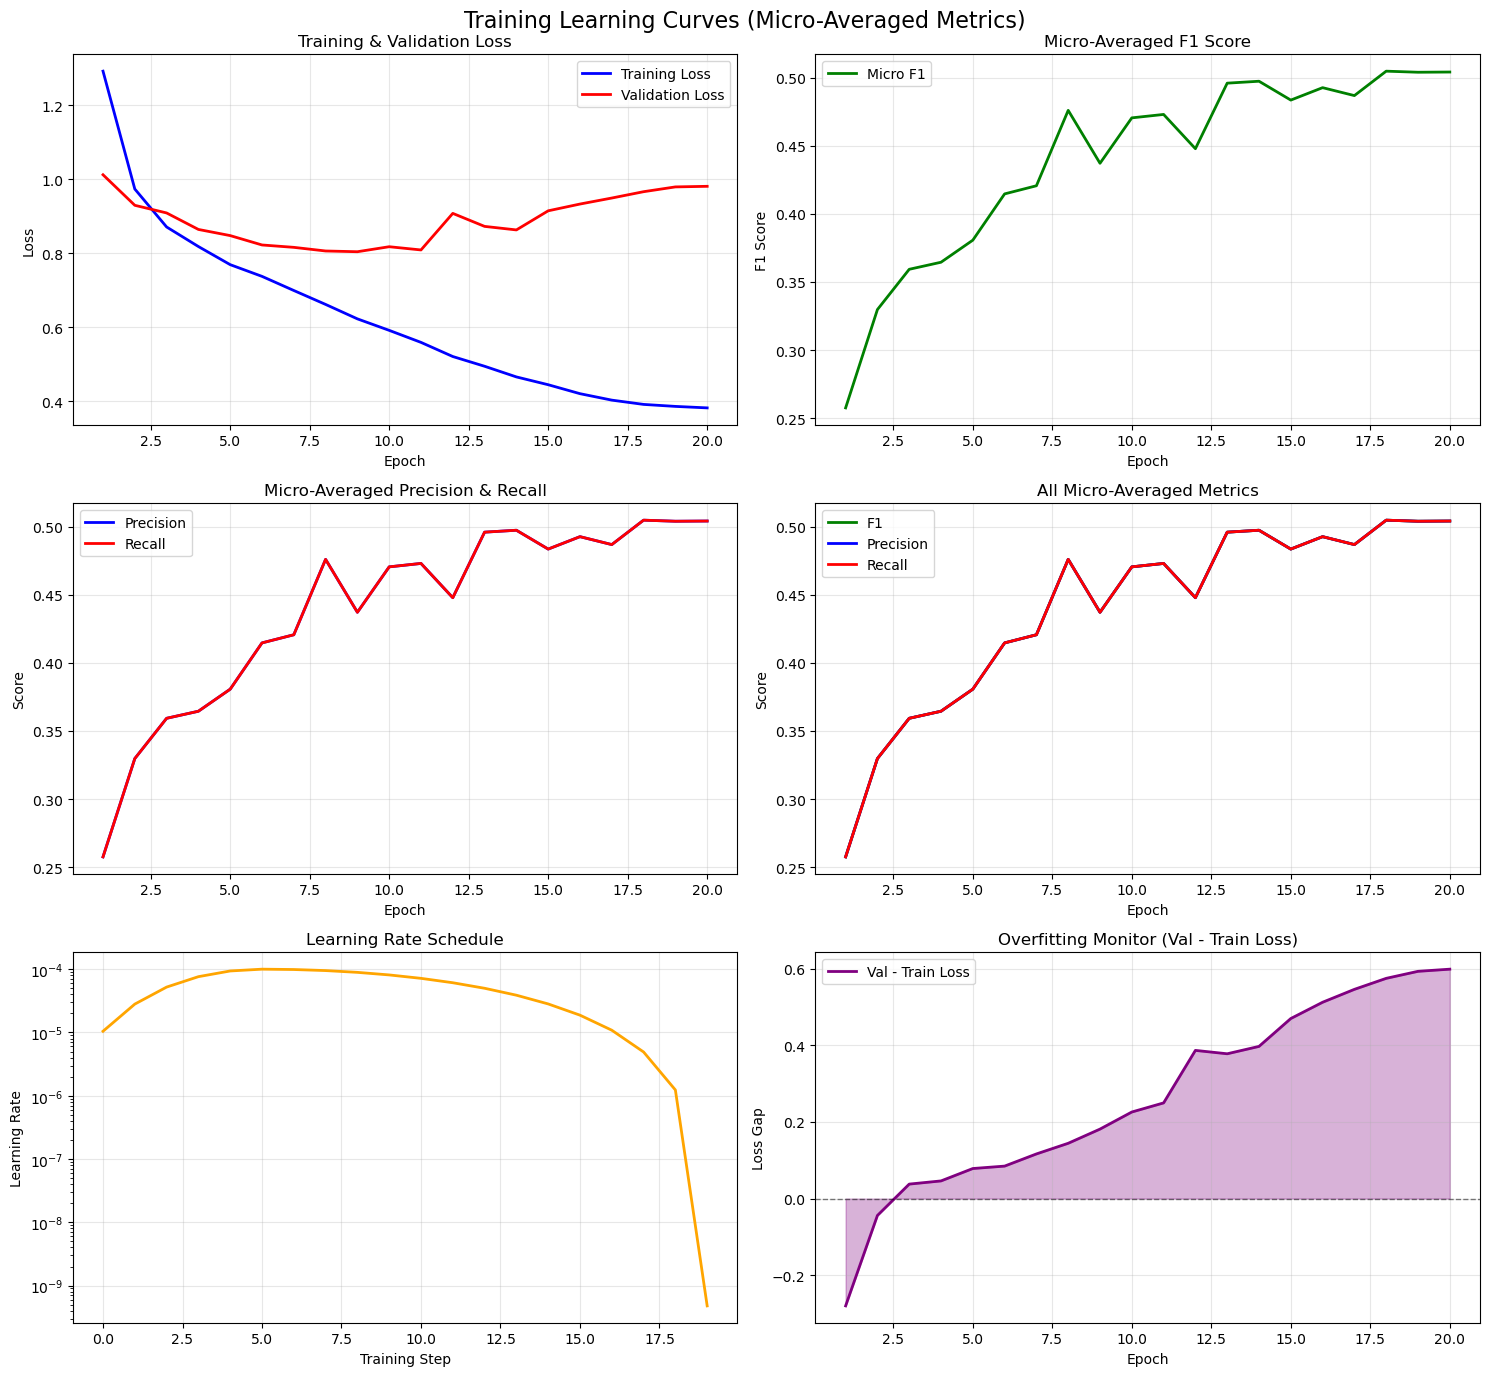


=== fold 2: train 2026 / val 507 ===
Analyzing date range in data...
MAG data - Date range: 2009-01-11 00:00:00 to 2025-11-13 00:00:00, Count: 5807
CDC data - Date range: 2018-03-07 00:00:00 to 2025-11-14 00:00:00, Count: 13652
Overall date range in data: 2009 - 2025
Date range updated: 2009 to 2025
Date range in data: 2009 to 2025
Using MIN_YEAR=2009, NUM_YEARS=17
Updated temporal dimensions: 204 features (12 months × 17 years)
Creating charge vocabulary from list with 709 unique charges
  Sources: charges (709 unique)
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.

📈 LR Scheduler: OneCycleLR
   Steps per epoch: 127
   Total steps: 2540
   Max LR: 1.00e-04
Before training - Allocated: 591.79 MB, Reserved: 1428.00 MB
🚀 Starting training with MultiLabelBinarizer
   Label processor: 20 labels
   Training sequences: 2026
   Validation sequences: 507
Epoch 1/20 - Allocated: 591.79 MB, 

Epoch 1/20: 100%|██████████| 127/127 [00:49<00:00,  2.55it/s, loss=1.2791, lr=1.04e-05, timesteps=62] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2534
   Recall:    0.2534
   F1-Score:  0.2534
   Steps processed: 4,168
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1263
  BOND_SET                                              735
  PRE_TRIAL_CONFERENCE_HELD                             677
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       629
  FIRST_APPEARANCE_HEARING_OCCURRED                     518
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 381
  CHARGES_REFUSED                                       357
  PLED_NOT_GUILTY_TO_CHARGES                            336
  PROBABLE_CAUSE_FOUND                                  295
  PLED_GUILTY_TO_CHARGES                                221
  BOND_NOT_SET                                          218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                194
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

Epoch 2/20: 100%|██████████| 127/127 [00:49<00:00,  2.54it/s, loss=0.8597, lr=2.81e-05, timesteps=71] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3067
   Recall:    0.3067
   F1-Score:  0.3067
   Steps processed: 4,168
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1263
  BOND_SET                                              735
  PRE_TRIAL_CONFERENCE_HELD                             677
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       629
  FIRST_APPEARANCE_HEARING_OCCURRED                     518
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 381
  CHARGES_REFUSED                                       357
  PLED_NOT_GUILTY_TO_CHARGES                            336
  PROBABLE_CAUSE_FOUND                                  295
  PLED_GUILTY_TO_CHARGES                                221
  BOND_NOT_SET                                          218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                194
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4664
   Recall:    0.4664
   F1-Score:  0.4664
   Steps processed: 4,168
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1263
  BOND_SET                                              735
  PRE_TRIAL_CONFERENCE_HELD                             677
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       629
  FIRST_APPEARANCE_HEARING_OCCURRED                     518
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 381
  CHARGES_REFUSED                                       357
  PLED_NOT_GUILTY_TO_CHARGES                            336
  PROBABLE_CAUSE_FOUND                                  295
  PLED_GUILTY_TO_CHARGES                                221
  BOND_NOT_SET                                          218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                194
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

Epoch 19/20: 100%|██████████| 127/127 [00:49<00:00,  2.57it/s, loss=0.3448, lr=1.23e-06, timesteps=67] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4685
   Recall:    0.4685
   F1-Score:  0.4685
   Steps processed: 4,168
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1263
  BOND_SET                                              735
  PRE_TRIAL_CONFERENCE_HELD                             677
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       629
  FIRST_APPEARANCE_HEARING_OCCURRED                     518
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 381
  CHARGES_REFUSED                                       357
  PLED_NOT_GUILTY_TO_CHARGES                            336
  PROBABLE_CAUSE_FOUND                                  295
  PLED_GUILTY_TO_CHARGES                                221
  BOND_NOT_SET                                          218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                194
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

Epoch 20/20: 100%|██████████| 127/127 [00:49<00:00,  2.57it/s, loss=0.4138, lr=4.78e-10, timesteps=88] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4682
   Recall:    0.4682
   F1-Score:  0.4682
   Steps processed: 4,168
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                 1263
  BOND_SET                                              735
  PRE_TRIAL_CONFERENCE_HELD                             677
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       629
  FIRST_APPEARANCE_HEARING_OCCURRED                     518
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 381
  CHARGES_REFUSED                                       357
  PLED_NOT_GUILTY_TO_CHARGES                            336
  PROBABLE_CAUSE_FOUND                                  295
  PLED_GUILTY_TO_CHARGES                                221
  BOND_NOT_SET                                          218
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                194
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          1

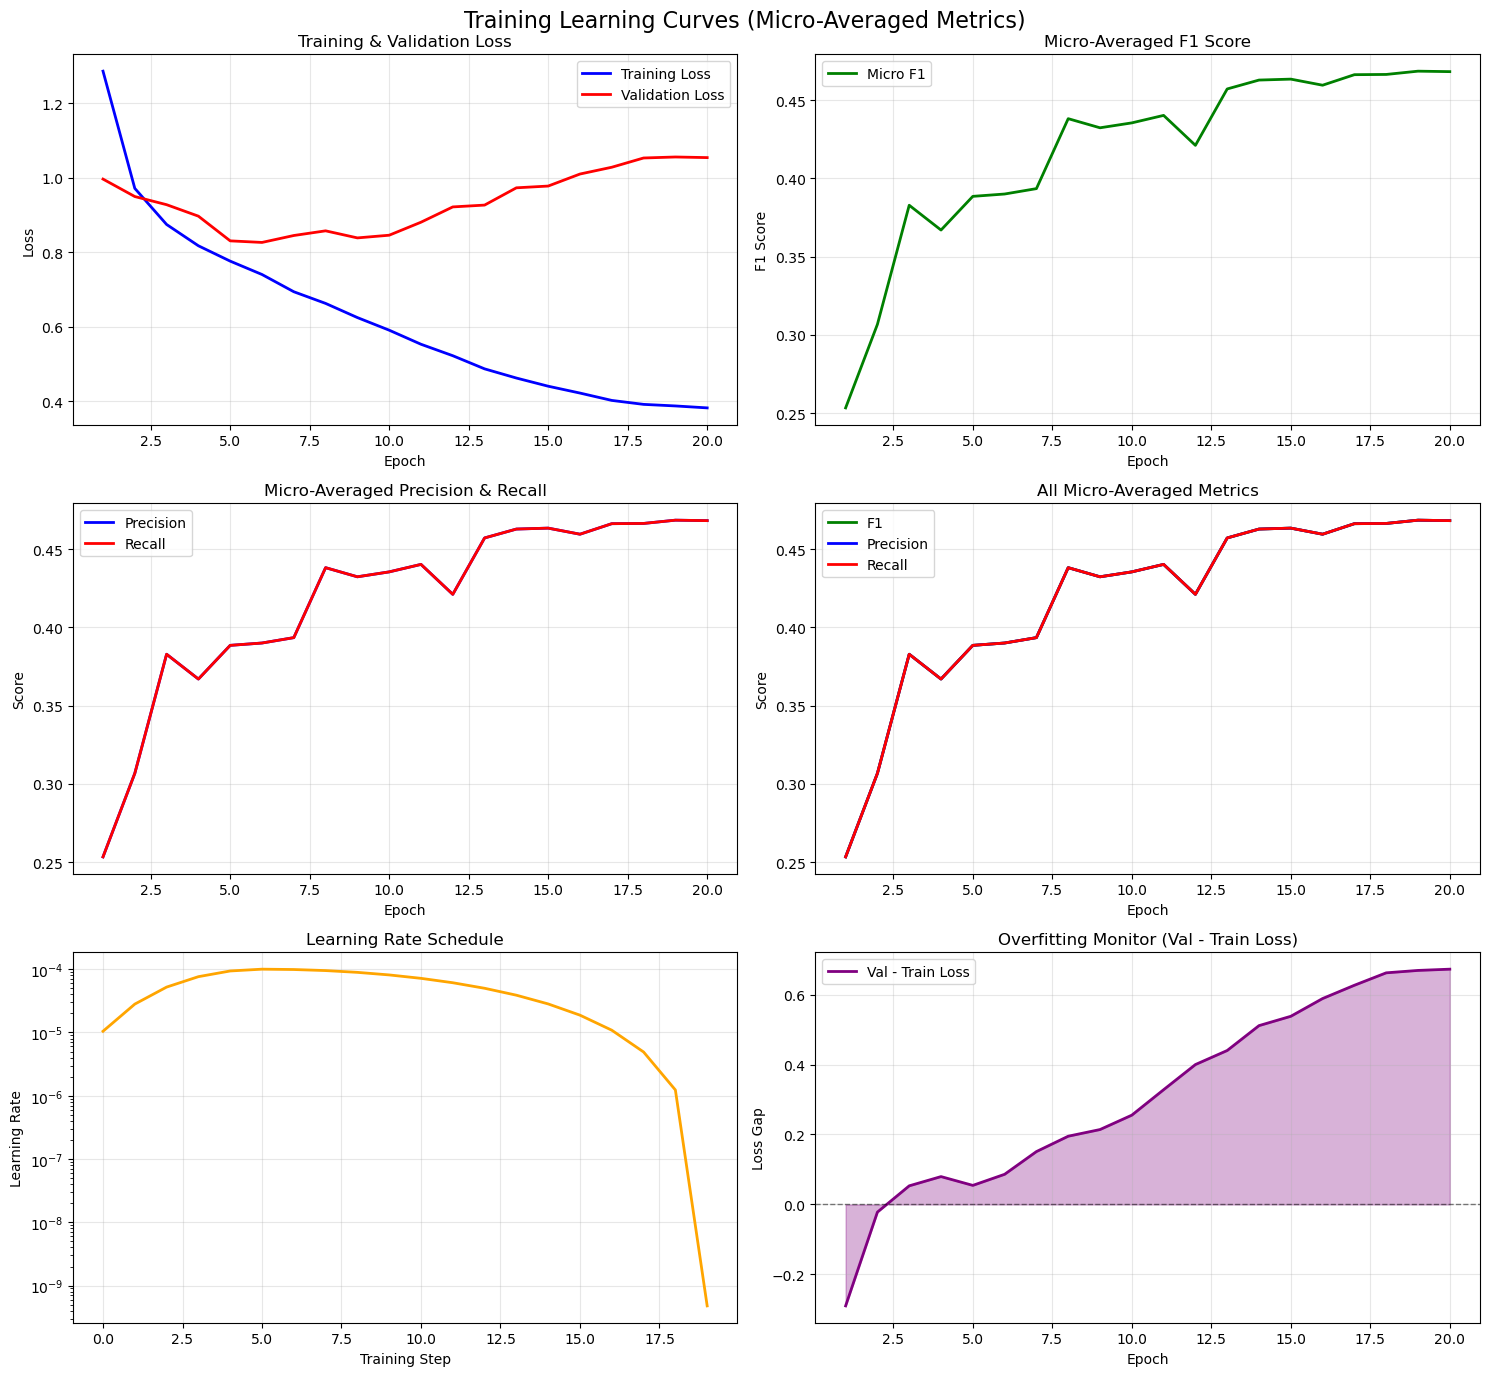


=== fold 3: train 2026 / val 507 ===
Analyzing date range in data...
MAG data - Date range: 2009-01-11 00:00:00 to 2025-11-13 00:00:00, Count: 5807
CDC data - Date range: 2018-03-07 00:00:00 to 2025-11-14 00:00:00, Count: 13652
Overall date range in data: 2009 - 2025
Date range updated: 2009 to 2025
Date range in data: 2009 to 2025
Using MIN_YEAR=2009, NUM_YEARS=17
Updated temporal dimensions: 204 features (12 months × 17 years)
Creating charge vocabulary from list with 709 unique charges
  Sources: charges (709 unique)
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.

📈 LR Scheduler: OneCycleLR
   Steps per epoch: 127
   Total steps: 2540
   Max LR: 1.00e-04
Before training - Allocated: 818.82 MB, Reserved: 1894.00 MB
🚀 Starting training with MultiLabelBinarizer
   Label processor: 20 labels
   Training sequences: 2026
   Validation sequences: 507
Epoch 1/20 - Allocated: 818.82 MB, 

Epoch 1/20: 100%|██████████| 127/127 [00:50<00:00,  2.51it/s, loss=1.0454, lr=1.04e-05, timesteps=103]



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2713
   Recall:    0.2713
   F1-Score:  0.2713
   Steps processed: 3,675
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  987
  BOND_SET                                              753
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       652
  PRE_TRIAL_CONFERENCE_HELD                             524
  FIRST_APPEARANCE_HEARING_OCCURRED                     523
  CHARGES_REFUSED                                       395
  PLED_NOT_GUILTY_TO_CHARGES                            319
  PROBABLE_CAUSE_FOUND                                  292
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 263
  PLED_GUILTY_TO_CHARGES                                219
  BOND_NOT_SET                                          187
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          160
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                1

Epoch 2/20: 100%|██████████| 127/127 [00:50<00:00,  2.49it/s, loss=0.9527, lr=2.81e-05, timesteps=95] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3415
   Recall:    0.3415
   F1-Score:  0.3415
   Steps processed: 3,675
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  987
  BOND_SET                                              753
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       652
  PRE_TRIAL_CONFERENCE_HELD                             524
  FIRST_APPEARANCE_HEARING_OCCURRED                     523
  CHARGES_REFUSED                                       395
  PLED_NOT_GUILTY_TO_CHARGES                            319
  PROBABLE_CAUSE_FOUND                                  292
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 263
  PLED_GUILTY_TO_CHARGES                                219
  BOND_NOT_SET                                          187
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          160
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                1

...

Epoch 11/20: 100%|██████████| 127/127 [00:51<00:00,  2.48it/s, loss=0.6046, lr=7.16e-05, timesteps=74] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4600
   Recall:    0.4600
   F1-Score:  0.4600
   Steps processed: 3,675
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  987
  BOND_SET                                              753
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       652
  PRE_TRIAL_CONFERENCE_HELD                             524
  FIRST_APPEARANCE_HEARING_OCCURRED                     523
  CHARGES_REFUSED                                       395
  PLED_NOT_GUILTY_TO_CHARGES                            319
  PROBABLE_CAUSE_FOUND                                  292
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 263
  PLED_GUILTY_TO_CHARGES                                219
  BOND_NOT_SET                                          187
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          160
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                1

Epoch 12/20: 100%|██████████| 127/127 [00:51<00:00,  2.49it/s, loss=0.4675, lr=6.10e-05, timesteps=62] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4536
   Recall:    0.4536
   F1-Score:  0.4536
   Steps processed: 3,675
   Cases processed: 507

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  987
  BOND_SET                                              753
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER       652
  PRE_TRIAL_CONFERENCE_HELD                             524
  FIRST_APPEARANCE_HEARING_OCCURRED                     523
  CHARGES_REFUSED                                       395
  PLED_NOT_GUILTY_TO_CHARGES                            319
  PROBABLE_CAUSE_FOUND                                  292
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                 263
  PLED_GUILTY_TO_CHARGES                                219
  BOND_NOT_SET                                          187
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED          160
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                1

Epoch 13/20: 100%|██████████| 127/127 [00:51<00:00,  2.46it/s, loss=0.4797, lr=4.99e-05, timesteps=81] 


In [ ]:
strategy = CONFIG["validation_strategy"]
seed_everything(CONFIG["seed"])

if strategy == "predefined_folds":
    folds = train_predefined_folds(model_sequences, label_sequences_raw, fold_ids)

elif strategy == "k_fold":
    from data.k_fold_methods import KFoldCVRunner
    runner = KFoldCVRunner(
        data=list(zip(model_sequences, label_sequences_raw)),
        model_creation_func=create_fresh_model, label_processor=label_processor, device=device,
        n_splits=CONFIG["k_fold_num_folds"], epochs=CONFIG["epochs"], batch_size=CONFIG["batch_size"],
        cache_manager=cache, shuffle=True, use_mixed_precision=CONFIG["use_mixed_precision"],
        use_learning_rate_scheduler=CONFIG["use_learning_rate_scheduler"],
        gradient_clip_norm=CONFIG["gradient_clip_norm"], random_state=CONFIG["seed"],
        weighted_loss=CONFIG["weighted_loss"],
    )
    cv = runner.run()
    folds = []
    for i in range(cv["n_splits"]):
        val_seq_labels, _ = runner.get_fold_val_data(i)
        folds.append({"fold": i + 1, "model": runner.load_fold_model(i), "val": val_seq_labels})

else:  # train_val_split
    from notebook_helpers import split_train_validation, train_model
    data = list(zip(model_sequences, label_sequences_raw))
    train_data, val_data = split_train_validation(data, test_size=CONFIG["val_split"],
                                                  random_state=CONFIG["seed"])
    model = create_fresh_model()
    trained, _ = train_model(model, train_data, label_processor, val_data, device,
                             epochs=CONFIG["epochs"], batch_size=CONFIG["batch_size"],
                             use_mixed_precision=CONFIG["use_mixed_precision"],
                             use_learning_rate_scheduler=CONFIG["use_learning_rate_scheduler"],
                             gradient_clip_norm=CONFIG["gradient_clip_norm"],
                             weighted_loss=CONFIG["weighted_loss"], fold_idx=None, cache_manager=cache)
    folds = [{"fold": 1, "model": trained, "val": val_data}]

print("\ntrained folds:", [f["fold"] for f in folds])

In [ ]:
from analysis.tablegenerator import TableGenerator
from notebook_helpers import (
    evaluate_model, evaluate_case_level,
    calculate_label_metrics_from_cases, save_label_metrics_to_excel,
)

models_dir = cache.get_cache_dir("models")
tg = TableGenerator(output_dir=models_dir)

for fd in folds:
    step_metrics = evaluate_model(fd["model"], fd["val"], device, label_processor, fold_idx=fd["fold"] - 1, cache_manager=cache)
    case_results = evaluate_case_level(fd["model"], fd["val"], label_processor)
    tg.add_main_fold_results(step_metrics=step_metrics, case_results=case_results,
                             model_name="Main Transformer", fold_idx=fd["fold"] - 1)
    case_df = calculate_label_metrics_from_cases(case_results, label_processor)
    save_label_metrics_to_excel(case_df, models_dir / f"case_level_fold_{fd['fold']}.xlsx")

# comparison + per-label workbooks
tg.generate_comparison_tables(output_dir=models_dir)
print("evaluation tables written to", models_dir)

In [ ]:
# optional baselines for the comparison tables
if CONFIG["run_baselines"]:
    try:
        from models.baseline_model import run_baseline
        from models.baseline_model_2 import run_random_baseline_comparison
        for fd in folds:
            tr = [c for c in zip(model_sequences, label_sequences_raw) if c not in fd["val"]]
            _, res = run_baseline(tr, fd["val"], label_processor)
            tg.add_baseline_fold_results(step_metrics=res, case_results=None,
                                         model_name="Most-Common Baseline", fold_idx=fd["fold"] - 1,
                                         type_of_model="Baseline", results_key="baseline_most_common")
        tg.generate_comparison_tables(output_dir=models_dir)
    except Exception as e:
        print("baseline step skipped:", e)

In [ ]:
INTERP_DIR = cache.get_cache_dir("interpretability_results")

def best_fold():
    return max(folds, key=lambda fd: _fold_score(fd))

def _fold_score(fd):
    try:
        cr = evaluate_case_level(fd["model"], fd["val"], label_processor)
        return float(getattr(cr, "mean_f1", None) or cr.get("avg_case_f1", 0.0))
    except Exception:
        return 0.0

bf = best_fold()
print("best fold:", bf["fold"])

In [ ]:
if CONFIG["ig"]["enabled"]:
    from notebook_helpers import (
        initialize_interpretability_analyzer, run_attribution_analysis,
        aggregate_component_importance, save_and_visualize_aggregate_importance,
    )
    seed_everything(CONFIG["seed"])
    analyzer = initialize_interpretability_analyzer(bf["model"], label_processor, device)
    results = run_attribution_analysis(analyzer, bf["val"], label_processor,
                                       num_cases=CONFIG["ig"]["n_cases"],
                                       method=CONFIG["ig"]["method"], n_steps=CONFIG["ig"]["n_steps"])
    stats_df = aggregate_component_importance(results)
    save_and_visualize_aggregate_importance(stats_df, INTERP_DIR)  # aggregate_feature_component_importance.xlsx

    try:
        from notebook_helpers import extract_top_attributed_words
        extract_top_attributed_words(analyzer, bf["val"], label_processor,
                                     top_n=CONFIG["ig"]["top_n_words"],
                                     output_path=INTERP_DIR / "top_30_words_captum.txt")
    except Exception as e:
        print("top-words attribution skipped:", e)
    print("IG done ->", INTERP_DIR)

In [ ]:
if CONFIG["sensitivity"]["enabled"]:
    from notebook_helpers import initialize_interpretability_analyzer
    seed_everything(CONFIG["seed"])
    analyzer = initialize_interpretability_analyzer(bf["model"], label_processor, device)
    val_sequences = [s for s, _ in bf["val"]]
    val_labels    = [l for _, l in bf["val"]]
    analyzer.run_counterfactual_magnitude_study(
        val_sequences=val_sequences, val_labels=val_labels, output_dir=INTERP_DIR,
        max_samples=CONFIG["sensitivity"]["max_samples"],
        top_n_labels=CONFIG["sensitivity"]["top_n_labels"],
        show_plots=False, parallel=CONFIG["sensitivity"]["parallel"],
    )
    print("counterfactual study done ->", INTERP_DIR)

In [ ]:
if CONFIG["clustering"]["enabled"]:
    seed_everything(CONFIG["seed"])
    import numpy as np
    from sklearn.manifold import TSNE
    from analysis.pca_vectors import (
        extract_all_pre_classifier_vectors, run_kmeans, evaluate_clustering,
        plot_multilabel_cluster_heatmap,
    )
    cc = CONFIG["clustering"]
    bf["model"].eval(); bf["model"].to(device)
    vectors, final_labels, case_labels_arr, _meta = extract_all_pre_classifier_vectors(
        bf["model"], bf["val"], label_processor, device,
        max_samples=cc["max_samples_per_fold"], use_teacher_forcing=cc["use_teacher_forcing"], verbose=True)

    xy = TSNE(n_components=2, random_state=CONFIG["seed"], perplexity=30, init="pca").fit_transform(np.asarray(vectors))
    km_labels, _ = run_kmeans(xy, nclusters=cc["n_clusters"], random_state=CONFIG["seed"])
    print("tsne kmeans metrics:", evaluate_clustering(xy, km_labels, None))

    # --- inline plot helpers (vendored from the clustering side-notebook) ---
    import matplotlib; matplotlib.use("Agg")
    import matplotlib.pyplot as plt; from matplotlib import cm; import math
    def scatter_2d(xy, colours, legend, title, out):
        xy = np.asarray(xy); fig, ax = plt.subplots(figsize=(12, 9))
        uniq = sorted(set(colours)); cmap = cm.get_cmap("tab10", len(uniq))
        for i, v in enumerate(uniq):
            m = np.array(colours) == v
            ax.scatter(xy[m, 0], xy[m, 1], c=[cmap(i)], label=legend[i], s=18, alpha=0.6,
                       edgecolors="w", linewidths=0.2)
        ax.set_xlabel("t-SNE dim 1"); ax.set_ylabel("t-SNE dim 2")
        ax.set_title(title, fontsize=13, fontweight="bold"); ax.legend(fontsize=9)
        fig.tight_layout(); fig.savefig(out, dpi=200, bbox_inches="tight"); plt.close(fig); print("saved", out)
    def label_grid(xy, label_matrix, names, clusters, out, title, max_cols=5):
        label_matrix = np.asarray(label_matrix); clusters = np.asarray(clusters)
        n, nl = label_matrix.shape; uniq = sorted(np.unique(clusters))
        cmap = cm.get_cmap("tab20", max(len(uniq), 1)); idx = {c: i for i, c in enumerate(uniq)}
        ncol = min(max_cols, nl); nrow = math.ceil(nl / ncol)
        fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow)); axes = np.atleast_1d(axes).flatten()
        for i, name in enumerate(names):
            ax = axes[i]; pos = label_matrix[:, i] == 1
            ax.scatter(xy[~pos, 0], xy[~pos, 1], c="lightgray", s=8, alpha=0.3)
            for c in uniq:
                m = pos & (clusters == c)
                if m.any(): ax.scatter(xy[m, 0], xy[m, 1], c=[cmap(idx[c])], s=14, alpha=0.7)
            ax.set_title(f"{name[:26]}\n(n={int(pos.sum())}, {100*pos.mean():.1f}%)", fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
        for j in range(nl, len(axes)): axes[j].axis("off")
        fig.suptitle(title, fontsize=14, fontweight="bold", y=1.02)
        fig.tight_layout(); fig.savefig(out, dpi=200, bbox_inches="tight"); plt.close(fig); print("saved", out)

    scatter_2d(xy, km_labels.tolist(), [f"Cluster {i}" for i in range(cc["n_clusters"])],
               f"t-SNE Embeddings — KMeans Clusters (Fold {bf['fold']} (best))",
               INTERP_DIR / "tsne_kmeans_clusters.png")
    label_grid(xy, case_labels_arr, label_processor.label_names, km_labels,
               INTERP_DIR / "tsne_label_grid.png",
               f"t-SNE Embeddings (Fold {bf['fold']} (best)) — Label Presence by Cluster")
    plot_multilabel_cluster_heatmap(km_labels, case_labels_arr, label_processor.label_names,
                                    output_path=INTERP_DIR / "tsne_multilabel_heatmap.png")
    print("clustering done ->", INTERP_DIR)

In [ ]:
import shutil
ARTIFACTS = {
    "evaluate": ["combined_table1.xlsx", "combined_table2.xlsx", "combined_table3.xlsx",
                 "Summary_All_Models.xlsx", "PerLabel_Long_Format.xlsx",
                 "average_fold_case_level_summary.xlsx"],
    "integrated_gradients": ["aggregate_feature_component_importance.xlsx", "top_30_words_captum.txt"],
    "sensitivity": ["counterfactual_summary.xlsx", "counterfactual_gender.xlsx", "counterfactual_race.xlsx",
                    "counterfactual_age.xlsx", "counterfactual_prior_case_count.xlsx",
                    "counterfactual_original_bond.xlsx"],
    "clustering": ["tsne_kmeans_clusters.png", "tsne_label_grid.png", "tsne_multilabel_heatmap.png"],
}
out = Path(CONFIG["outputs_dir"]); out.mkdir(parents=True, exist_ok=True)
run_root = Path(CONFIG["cache_root"]) / CONFIG["run_name"]
print("artifact check:")
for stage, files in ARTIFACTS.items():
    print(f"[{stage}]")
    for fn in files:
        hits = list(run_root.rglob(fn))
        if hits:
            src = max(hits, key=lambda p: p.stat().st_mtime)
            shutil.copy2(src, out / fn); print(f"   OK   {fn}")
        else:
            print(f"   MISS {fn}")
print("\noutputs ->", out.resolve())